In [4]:
# Ejecuta esta celda en Colab para subir los tres algoritmos
from google.colab import files
files.upload()

Saving SCA.py to SCA (1).py
Saving mainPSO.py to mainPSO (1).py
Saving DE.py to DE (1).py


{'SCA (1).py': b'\nfrom __future__ import annotations\n\nimport argparse\nimport csv\nfrom pathlib import Path\nfrom typing import Any, Callable, Iterator\n\nimport numpy as np\n\n\ndef sphere(x: np.ndarray) -> float:\n    """Sphere estandar: sum(x_i**2), minimo teorico 0."""\n    v = np.asarray(x, dtype=float)\n    return float(np.dot(v, v))\n\n\ndef ackley(x: np.ndarray) -> float:\n    """Ackley estandar: minimo global f(0)=0."""\n    v = np.asarray(x, dtype=float)\n    return float(\n        -20.0 * np.exp(-0.2 * np.sqrt(np.mean(v**2)))\n        - np.exp(np.mean(np.cos(2.0 * np.pi * v)))\n        + 20.0 + np.e\n    )\n\n\nSphere = sphere\nAckley = ackley\n\n\ndef fobj(x: np.ndarray) -> float:\n    """Funcion del SCA.py original: media de cuadrados (=Sphere/d)."""\n    v = np.asarray(x, dtype=float)\n    if v.size == 0:\n        raise ValueError("La funcion requiere al menos una variable.")\n    return float(np.mean(v**2))\n\n\ndef _parse_problem(problem: dict[str, Any]) -> tuple[Cal

In [9]:
"""Benchmark reproducible PSO vs SCA vs DE sobre Ackley.

Requiere en el mismo directorio (o en /content de Google Colab):
    mainPSO_propio.py, mainSCA_propio.py, mainDE_propio.py

Uso en Colab:
    !python /content/test_runner_PSO_SCA_DE.py --runs 30
Uso local:
    python test_runner_PSO_SCA_DE.py --runs 30 --dim 10 --iters 1000

Los tres algoritmos reciben el mismo numero de individuos, generaciones y
presupuesto de evaluaciones. Todos minimizan Ackley.
"""
from __future__ import annotations

import argparse
import csv
import sys
from pathlib import Path

import matplotlib
matplotlib.use("Agg")  # Guarda la grafica tambien en sesiones sin pantalla.
import matplotlib.pyplot as plt
import numpy as np


def prepare_imports():
    """Busca los modulos propios junto al runner, en Colab o en cwd."""
    script_dir = Path(__file__).resolve().parent if '__file__' in globals() else Path.cwd()
    candidates = [Path.cwd(), script_dir, Path('/content'), Path('/mnt/data')]
    required = ('mainPSO.py', 'SCA.py', 'DE.py')
    for folder in candidates:
        if all((folder / name).is_file() for name in required):
            sys.path.insert(0, str(folder))
            return folder
    raise FileNotFoundError(
        'Faltan los modulos mainPSO_propio.py, mainSCA_propio.py y mainDE_propio.py. '
        'Subelos juntos a /content o a la carpeta del script.'
    )


def ackley(x: np.ndarray) -> float:
    """Ackley clasica; minimo global teorico igual a 0 en x = 0."""
    x = np.asarray(x, dtype=float)
    n = x.size
    return float(-20.0 * np.exp(-0.2 * np.sqrt(np.sum(x**2) / n))
                 - np.exp(np.sum(np.cos(2.0 * np.pi * x)) / n)
                 + 20.0 + np.e)


def run_benchmark(dim=10, pop_size=50, max_iter=1000, n_runs=1,
                  base_seed=1000, output_dir=None, make_plot=True):
    if dim < 1 or pop_size < 4 or max_iter < 1 or n_runs < 1:
        raise ValueError('dim>=1, pop_size>=4, max_iter>=1 y n_runs>=1 son obligatorios.')

    base_dir = prepare_imports()
    from mainPSO import PSO
    from SCA import SCA
    from DE import DE

    output_dir = Path(output_dir) if output_dir else base_dir
    output_dir.mkdir(parents=True, exist_ok=True)

    problem = {
        'CostFunction': ackley,
        'nVar': dim,
        'VarMin': -32.768,
        'VarMax': 32.768,
    }
    algorithms = {
        'PSO': (PSO, {'c1': 1.4962, 'c2': 1.4962, 'w': 0.7298,
                      'wdamp': 1.0, 'update_mode': 'asynchronous'}),
        'SCA': (SCA, {'a': 2.0, 'elitism': False}),
        'DE':  (DE,  {'F': 0.8, 'CR': 0.7, 'strategy': 'rand1',
                      'update_mode': 'asynchronous'}),
    }

    results = {}
    expected_evaluations = pop_size * (max_iter + 1)
    for name, (fn, params) in algorithms.items():
        curves = np.empty((n_runs, max_iter), dtype=float)
        positions = np.empty((n_runs, dim), dtype=float)
        for r in range(n_runs):
            gbest, _ = fn(problem, MaxIter=max_iter, PopSize=pop_size,
                          seed=base_seed + r, verbose=False, **params)
            curves[r] = np.asarray(gbest['history'], dtype=float)
            positions[r] = np.asarray(gbest['position'], dtype=float)
            assert curves[r].shape == (max_iter,)
            assert np.all(np.diff(curves[r]) <= 1e-12), f'Curva no monotonica en {name}'
            assert gbest['function_evaluations'] == expected_evaluations
            assert np.isclose(ackley(positions[r]), gbest['cost'], atol=1e-12)
        results[name] = {'curves': curves, 'finals': curves[:, -1],
                         'positions': positions}

    print('=' * 78)
    print(f'TEST RUNNER RESULTS -- Ackley (dim={dim}, pop={pop_size}, '
          f'iters={max_iter}, runs={n_runs})')
    print('Global optimum: f(0,...,0) = 0')
    print(f'Evaluations per run and algorithm: {expected_evaluations:,}')
    print('=' * 78)
    for name, result in results.items():
        values = result['finals']
        std = float(values.std(ddof=1)) if n_runs > 1 else float('nan')
        print(f'{name:<5} | best={values.min():.6e} | mean={values.mean():.6e} | '
              f'std={std:.6e} | worst={values.max():.6e}')
    print('=' * 78)
    checkpoints = sorted(set([0, 9, 49, 99, 149, max_iter - 1]))
    for name, result in results.items():
        curve = result['curves']
        med = np.median(curve, axis=0)
        print(f'{name:<5} iteration-wise global best (median over {n_runs} runs):')
        for step in checkpoints:
            if step < max_iter:
                print(f'    iter {step + 1:4d} : {med[step]:.6e}')
        print()

    # CSV final: una fila por ejecucion y algoritmo.
    summary_path = output_dir / 'ackley_resultados_finales.csv'
    with summary_path.open('w', newline='', encoding='utf-8') as f:
        writer = csv.writer(f)
        writer.writerow(['algorithm', 'run', 'seed', 'final_fitness', 'evaluations'])
        for name, result in results.items():
            for r, value in enumerate(result['finals']):
                writer.writerow([name, r + 1, base_seed + r, f'{value:.16e}',
                                 expected_evaluations])

    # CSV de todas las curvas, para analisis posterior o graficas.
    curves_path = output_dir / 'ackley_convergencia_curvas.csv'
    with curves_path.open('w', newline='', encoding='utf-8') as f:
        writer = csv.writer(f)
        writer.writerow(['algorithm', 'run', 'iteration', 'global_best_fitness'])
        for name, result in results.items():
            for r, curve in enumerate(result['curves']):
                for step, value in enumerate(curve, start=1):
                    writer.writerow([name, r + 1, step, f'{value:.16e}'])

    fig_path = output_dir / 'ackley_convergence.png'
    if make_plot:
        plt.figure(figsize=(10, 6))
        iterations = np.arange(1, max_iter + 1)
        for name, result in results.items():
            curves = result['curves']
            med = np.median(curves, axis=0)
            q25, q75 = np.percentile(curves, [25, 75], axis=0)
            # Solo para graficar: la escala logaritmica no admite valores <= 0.
            floor = np.finfo(float).eps
            plt.plot(iterations, np.maximum(med, floor), lw=2, label=name)
            if n_runs > 1:
                plt.fill_between(iterations, np.maximum(q25, floor),
                                 np.maximum(q75, floor), alpha=0.15)
        plt.yscale('log')
        plt.xlabel('Iteration')
        plt.ylabel('Global best fitness (log scale)')
        plt.title(f'Ackley convergence: median of {n_runs} runs' +
                  (', IQR shaded' if n_runs > 1 else ''))
        plt.grid(True, which='both', linestyle=':', alpha=0.5)
        plt.legend()
        plt.tight_layout()
        plt.savefig(fig_path, dpi=160)
        plt.close()

    print(f'Resumen CSV: {summary_path}')
    print(f'Curvas CSV: {curves_path}')
    if make_plot:
        print(f'Grafica: {fig_path}')
    return results



In [10]:
# Configuración experimental
DIM = 10
POP_SIZE = 50
MAX_ITER = 1000
N_RUNS = 1   # Cambia a 30 para un estudio con multiples ejecuciones
SEED = 1000

results = run_benchmark(dim=DIM, pop_size=POP_SIZE, max_iter=MAX_ITER,
                        n_runs=N_RUNS, base_seed=SEED, output_dir='/content')

TEST RUNNER RESULTS -- Ackley (dim=10, pop=50, iters=1000, runs=1)
Global optimum: f(0,...,0) = 0
Evaluations per run and algorithm: 50,050
PSO   | best=3.996803e-15 | mean=3.996803e-15 | std=nan | worst=3.996803e-15
SCA   | best=3.996803e-15 | mean=3.996803e-15 | std=nan | worst=3.996803e-15
DE    | best=2.521589e-08 | mean=2.521589e-08 | std=nan | worst=2.521589e-08
PSO   iteration-wise global best (median over 1 runs):
    iter    1 : 1.747511e+01
    iter   10 : 9.712699e+00
    iter   50 : 1.958385e+00
    iter  100 : 3.735246e-02
    iter  150 : 1.767122e-03
    iter 1000 : 3.996803e-15

SCA   iteration-wise global best (median over 1 runs):
    iter    1 : 1.966444e+01
    iter   10 : 1.966444e+01
    iter   50 : 1.766530e+01
    iter  100 : 1.638582e+01
    iter  150 : 1.092288e+01
    iter 1000 : 3.996803e-15

DE    iteration-wise global best (median over 1 runs):
    iter    1 : 1.966444e+01
    iter   10 : 1.867147e+01
    iter   50 : 1.388064e+01
    iter  100 : 7.122159e+0

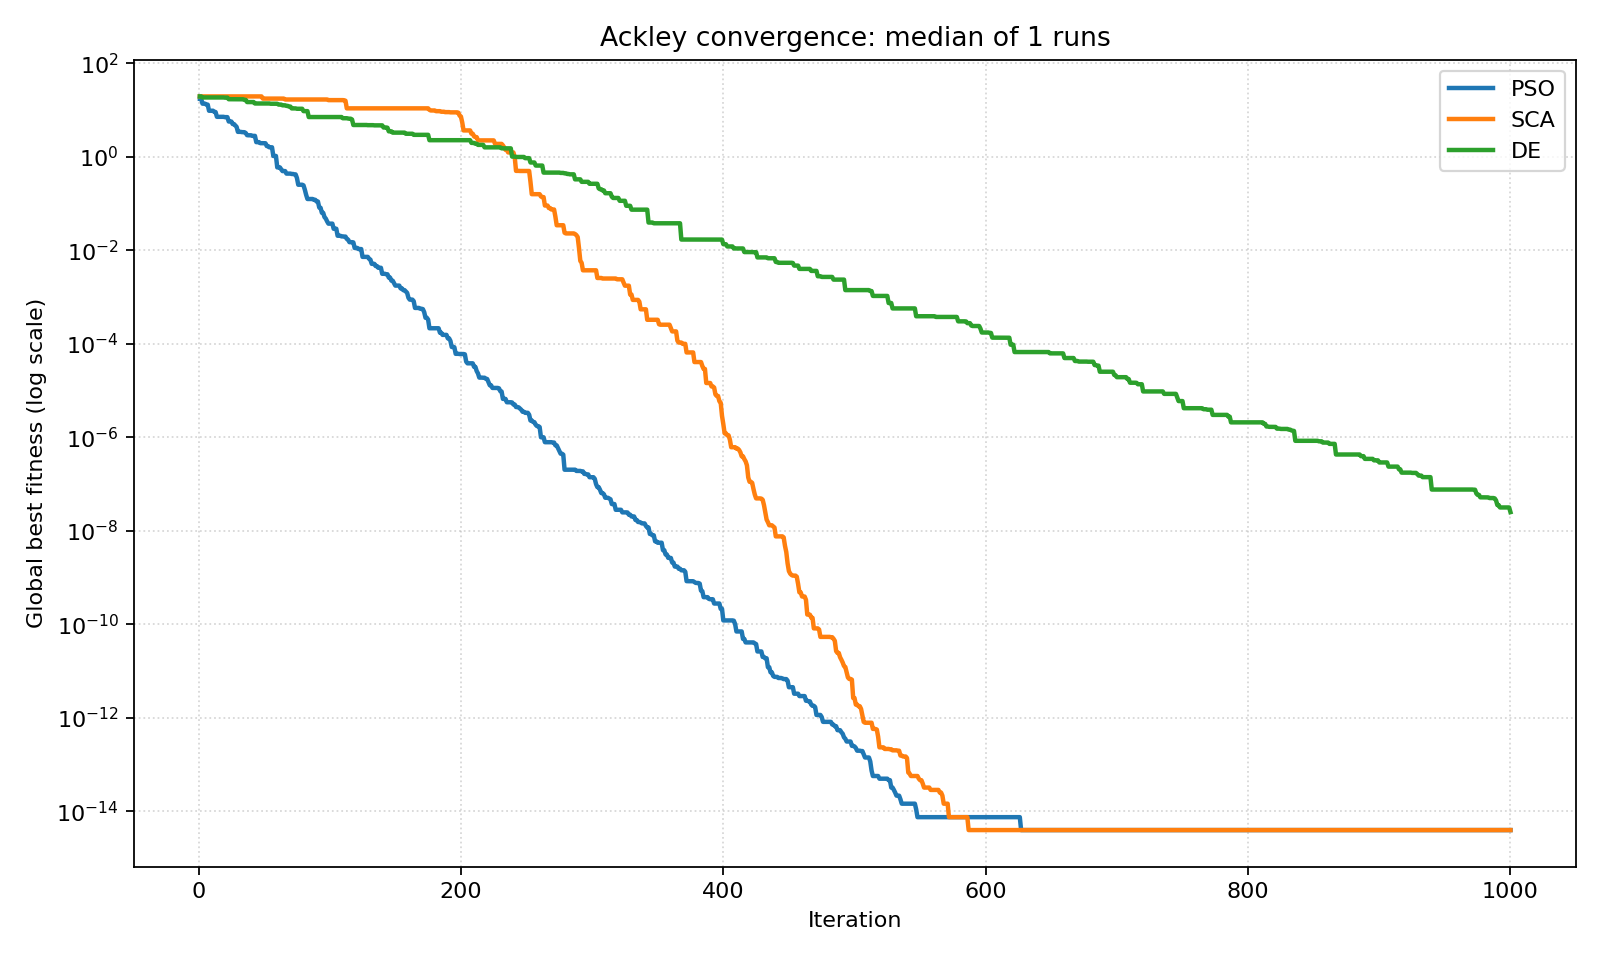

In [11]:
from IPython.display import display, Image
display(Image(filename='/content/ackley_convergence.png'))

Cargado: mainPSO -> /content/mainPSO.py
Cargado: DE -> /content/DE.py
Cargado: SCA -> /content/SCA.py

SPHERE | D=10 | Población=50 | Iteraciones=1000 | Runs=1
Óptimo global: 0 | Evaluaciones por corrida: 50,050
PSO   | best=1.297617e-51 | mean=1.297617e-51 | std=nan | worst=1.297617e-51
SCA   | best=1.218751e-26 | mean=1.218751e-26 | std=nan | worst=1.218751e-26
DE    | best=2.844312e-15 | mean=2.844312e-15 | std=nan | worst=2.844312e-15

PSO — Mediana del mejor global por iteración:
  iter    1: 5.362692e+03
  iter   10: 8.750804e+02
  iter   50: 3.002910e+00
  iter  100: 6.045097e-03
  iter  150: 1.258294e-05
  iter 1000: 1.297617e-51

SCA — Mediana del mejor global por iteración:
  iter    1: 1.544071e+04
  iter   10: 1.230769e+04
  iter   50: 3.586158e+03
  iter  100: 2.412292e+03
  iter  150: 5.654855e+02
  iter 1000: 1.218751e-26

DE — Mediana del mejor global por iteración:
  iter    1: 1.544071e+04
  iter   10: 7.510939e+03
  iter   50: 2.104247e+03
  iter  100: 2.749718e+02
 

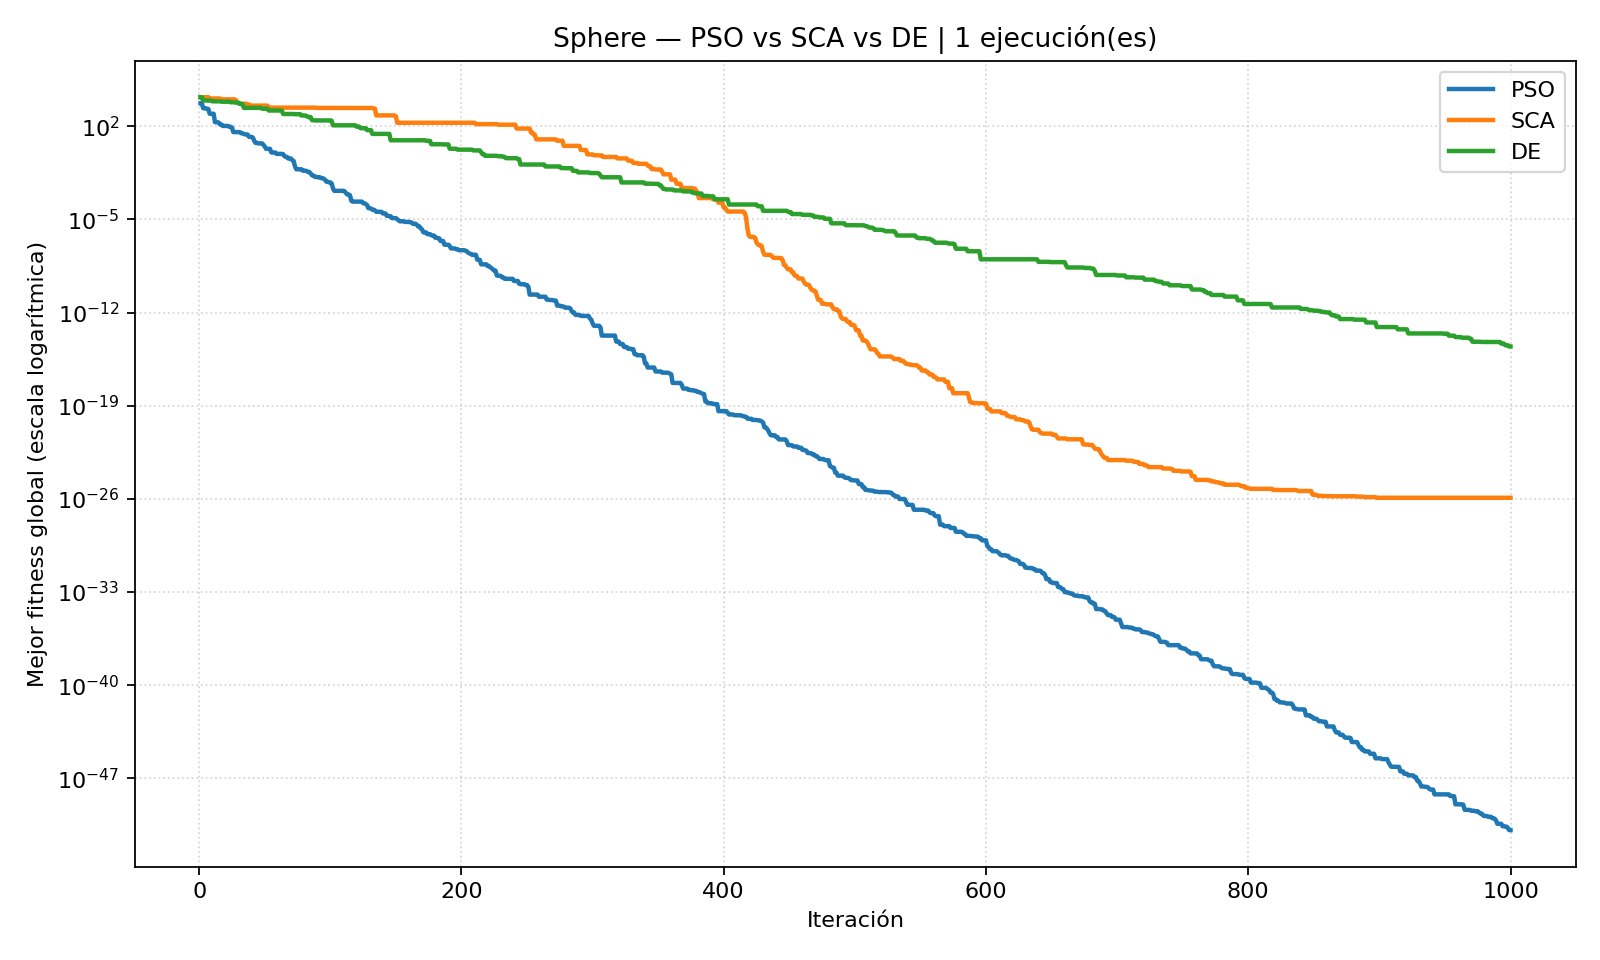

In [29]:
"""Test Runner Sphere compatible con mainPSO.py, DE.py y SCA.py.

Ejecutar todo en una celda de Colab o como archivo Python.
No usa argparse ni ejecuta las demostraciones de los módulos originales.
"""

import ast
import contextlib
import csv
import inspect
import io
import re
import types
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

# ================================================================
# 1. CONFIGURACIÓN: modifica estos valores en Google Colab
# ================================================================
DIM = 10
POP_SIZE = 50
MAX_ITER = 1000
N_RUNS = 1              # Cambia a 30 para el experimento estadístico
BASE_SEED = 1000
VAR_MIN, VAR_MAX = -100.0, 100.0
OUTPUT_DIR = Path('/content/resultados_sphere') if Path('/content').is_dir() else Path('resultados_sphere')


def find_module_file(module_name):
    """Encuentra mainPSO.py / MAINPSO.py, DE.py y SCA.py sin importar mayúsculas."""
    folders = [Path('/content'), Path.cwd(), Path('/mnt/data')]
    for folder in folders:
        if folder.is_dir():
            for path in folder.glob('*.py'):
                if path.stem.lower() == module_name.lower():
                    return path
    return None


def load_without_demo(path):
    """Carga imports y definiciones, pero NO ejecuta demos al final de archivos viejos."""
    source = path.read_text(encoding='utf-8-sig')
    # Ignorar etiquetas de visualización añadidas accidentalmente al copiar el archivo.
    source = '\n'.join(line for line in source.splitlines()
                       if not line.lstrip().startswith('Mostrando '))
    tree = ast.parse(source, filename=str(path))
    allowed = (ast.Import, ast.ImportFrom, ast.FunctionDef,
               ast.AsyncFunctionDef, ast.ClassDef)
    clean_tree = ast.Module(body=[node for node in tree.body if isinstance(node, allowed)],
                            type_ignores=[])
    ast.fix_missing_locations(clean_tree)
    module = types.ModuleType(path.stem)
    module.__file__ = str(path)
    exec(compile(clean_tree, str(path), 'exec'), module.__dict__)
    return module


# Buscar los tres archivos; permitir cargarlos de forma interactiva en Colab.
requested = ('mainPSO', 'DE', 'SCA')
paths = {name: find_module_file(name) for name in requested}
missing = [name + '.py' for name in requested if paths[name] is None]
if missing:
    print('Faltan los archivos:', ', '.join(missing))
    try:
        from google.colab import files
        print('Selecciona tus tres archivos Python originales en el diálogo.')
        files.upload()
    except ImportError:
        pass
    paths = {name: find_module_file(name) for name in requested}
    missing = [name + '.py' for name in requested if paths[name] is None]
    if missing:
        raise FileNotFoundError('Sube estos archivos a /content: ' + ', '.join(missing))

modules = {name: load_without_demo(path) for name, path in paths.items()}
for name, path in paths.items():
    print(f'Cargado: {name} -> {path}')


# ================================================================
# 2. FUNCIÓN SPHERE (NO la media de los cuadrados)
# ================================================================
def sphere(x):
    x = np.asarray(x, dtype=float)
    return float(np.sum(x ** 2))


problem = {'CostFunction': sphere, 'nVar': DIM,
           'VarMin': VAR_MIN, 'VarMax': VAR_MAX}
bounds = [(VAR_MIN, VAR_MAX)] * DIM


def supported_kwargs(function, kwargs):
    """Pasa solo opciones que el algoritmo realmente admite."""
    parameters = inspect.signature(function).parameters
    return {key: value for key, value in kwargs.items() if key in parameters}


def run_pso(seed):
    """Usa la curva propia si existe, o extrae los mensajes del PSO original."""
    np.random.seed(seed)
    function = modules['mainPSO'].PSO
    options = {'MaxIter': MAX_ITER, 'PopSize': POP_SIZE,
               'c1': 1.4962, 'c2': 1.4962, 'w': 0.7298, 'wdamp': 1.0,
               'seed': seed, 'verbose': False, 'update_mode': 'asynchronous'}
    captured = io.StringIO()
    with contextlib.redirect_stdout(captured):
        best, _ = function(problem, **supported_kwargs(function, options))

    if 'history' in best:
        curve = np.asarray(best['history'], dtype=float)
    else:
        # PSO original: "Iteration 0: Best Cost = ..."
        regex = r'Iteration\s+\d+:\s*Best Cost\s*=\s*([^\s]+)'
        curve = np.array([float(value) for value in
                          re.findall(regex, captured.getvalue())], dtype=float)
    return curve, np.asarray(best['position'], dtype=float).copy()


def run_sca(seed):
    np.random.seed(seed)
    module = modules['SCA']
    if hasattr(module, 'SCA'):
        function = module.SCA
        options = {'MaxIter': MAX_ITER, 'PopSize': POP_SIZE, 'a': 2.0,
                   'seed': seed, 'verbose': False, 'elitism': False}
        with contextlib.redirect_stdout(io.StringIO()):
            best, _ = function(problem, **supported_kwargs(function, options))
        return np.asarray(best['history'], dtype=float), np.asarray(best['position']).copy()

    # SCA original usa un generador; conservar el mejor histórico.
    curve = np.empty(MAX_ITER)
    best_fitness, best_position = np.inf, None
    with contextlib.redirect_stdout(io.StringIO()):
        for it, (position, cost) in enumerate(
                module.sca(sphere, bounds=bounds, popsize=POP_SIZE, its=MAX_ITER)):
            if cost < best_fitness:
                best_fitness = float(cost)
                best_position = np.asarray(position, dtype=float).copy()
            curve[it] = best_fitness
    return curve, best_position


def run_de(seed):
    np.random.seed(seed)
    module = modules['DE']
    if hasattr(module, 'DE'):
        function = module.DE
        options = {'MaxIter': MAX_ITER, 'PopSize': POP_SIZE, 'F': 0.8,
                   'CR': 0.7, 'strategy': 'rand1', 'seed': seed,
                   'verbose': False, 'update_mode': 'asynchronous'}
        with contextlib.redirect_stdout(io.StringIO()):
            best, _ = function(problem, **supported_kwargs(function, options))
        return np.asarray(best['history'], dtype=float), np.asarray(best['position']).copy()

    # DE original también es un generador; copiar las posiciones inmediatamente.
    curve = np.empty(MAX_ITER)
    best_fitness, best_position = np.inf, None
    with contextlib.redirect_stdout(io.StringIO()):
        for it, (position, cost) in enumerate(module.de(
                sphere, bounds=bounds, mut=0.8, crossp=0.7,
                popsize=POP_SIZE, its=MAX_ITER)):
            if cost < best_fitness:
                best_fitness = float(cost)
                best_position = np.asarray(position, dtype=float).copy()
            curve[it] = best_fitness
    return curve, best_position


# ================================================================
# 3. EVALUACIÓN Y ESTADÍSTICAS
# ================================================================
if not (DIM >= 1 and POP_SIZE >= 4 and MAX_ITER >= 1 and N_RUNS >= 1):
    raise ValueError('Configura DIM>=1, POP_SIZE>=4, MAX_ITER>=1, N_RUNS>=1.')

runners = {'PSO': run_pso, 'SCA': run_sca, 'DE': run_de}
results = {}
for name, function in runners.items():
    curves, positions = [], []
    for run in range(N_RUNS):
        curve, position = function(BASE_SEED + run)
        if curve.shape != (MAX_ITER,):
            raise ValueError(f'{name}: se esperaban {MAX_ITER} valores, llegaron {curve.shape}.')
        if not np.all(np.isfinite(curve)):
            raise ValueError(f'{name}: existen fitness no finitos.')
        if np.any(np.diff(curve) > 1e-10):
            raise ValueError(f'{name}: la curva del mejor histórico no es monótona.')
        if not np.isclose(sphere(position), curve[-1], rtol=1e-5, atol=1e-12):
            raise ValueError(f'{name}: el fitness no coincide con la mejor posición.')
        curves.append(curve)
        positions.append(position)
    curves = np.asarray(curves)
    results[name] = {'curves': curves, 'finals': curves[:, -1],
                     'positions': np.asarray(positions)}

print('\n' + '=' * 77)
print(f'SPHERE | D={DIM} | Población={POP_SIZE} | Iteraciones={MAX_ITER} | Runs={N_RUNS}')
print(f'Óptimo global: 0 | Evaluaciones por corrida: {POP_SIZE * (MAX_ITER + 1):,}')
print('=' * 77)
for name, values in results.items():
    f = values['finals']
    std = float(np.std(f, ddof=1)) if N_RUNS > 1 else float('nan')
    print(f'{name:<5} | best={f.min():.6e} | mean={f.mean():.6e} | '
          f'std={std:.6e} | worst={f.max():.6e}')

checkpoints = [it for it in (1, 10, 50, 100, 150, MAX_ITER) if it <= MAX_ITER]
for name, values in results.items():
    print(f'\n{name} — Mediana del mejor global por iteración:')
    median = np.median(values['curves'], axis=0)
    for it in sorted(set(checkpoints)):
        print(f'  iter {it:4d}: {median[it - 1]:.6e}')


# ================================================================
# 4. GUARDAR DATOS Y GRAFICAR
# ================================================================
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
with (OUTPUT_DIR / 'sphere_resultados_finales.csv').open('w', newline='') as f:
    out = csv.writer(f)
    out.writerow(['algorithm', 'run', 'seed', 'final_fitness'])
    for name, values in results.items():
        for run, fitness in enumerate(values['finals']):
            out.writerow([name, run + 1, BASE_SEED + run, f'{fitness:.16e}'])

with (OUTPUT_DIR / 'sphere_convergencia_curvas.csv').open('w', newline='') as f:
    out = csv.writer(f)
    out.writerow(['algorithm', 'run', 'iteration', 'best_fitness'])
    for name, values in results.items():
        for run, curve in enumerate(values['curves']):
            for it, fitness in enumerate(curve, start=1):
                out.writerow([name, run + 1, it, f'{fitness:.16e}'])

plt.figure(figsize=(10, 6))
iterations = np.arange(1, MAX_ITER + 1)
floor = np.finfo(float).tiny  # eps oculta valores correctos inferiores a 1e-16
for name, values in results.items():
    curves = values['curves']
    median = np.maximum(np.median(curves, axis=0), floor)
    plt.plot(iterations, median, lw=2, label=name)
    if N_RUNS > 1:
        q25, q75 = np.percentile(curves, (25, 75), axis=0)
        plt.fill_between(iterations, np.maximum(q25, floor),
                         np.maximum(q75, floor), alpha=0.15)
plt.yscale('log')
plt.xlabel('Iteración')
plt.ylabel('Mejor fitness global (escala logarítmica)')
plt.title(f'Sphere — PSO vs SCA vs DE | {N_RUNS} ejecución(es)')
plt.grid(True, which='both', linestyle=':', alpha=0.5)
plt.legend()
plt.tight_layout()
image_path = OUTPUT_DIR / 'sphere_convergence.png'
plt.savefig(image_path, dpi=160)
plt.close()

print(f'\nResultados y gráfica guardados en: {OUTPUT_DIR.resolve()}')
try:
    from IPython.display import display, Image
    display(Image(filename=str(image_path)))
except ImportError:
    pass
